# 38. End-to-End RAG Evaluation

Measure retrieval (hit rate, MRR) and generation (correctness, faithfulness) over a golden set.

[![X](https://img.shields.io/badge/X-000000?style=for-the-badge&logo=x&logoColor=white)](https://x.com/techwith_ram) [![GitHub](https://img.shields.io/badge/GitHub-181717?style=for-the-badge&logo=github&logoColor=white)](https://github.com/Ramakm) [![LinkedIn](https://img.shields.io/badge/LinkedIn-0A66C2?style=for-the-badge&logo=linkedin&logoColor=white)](https://www.linkedin.com/in/ramakrushnamohapatra/) [![Instagram](https://img.shields.io/badge/Instagram-E4405F?style=for-the-badge&logo=instagram&logoColor=white)](https://instagram.com/techwith.ram) [![Medium](https://img.shields.io/badge/Medium-000000?style=for-the-badge&logo=medium&logoColor=white)](https://medium.com/@techwithram)

## Why this matters

A RAG system can fail at two points - **retrieval** (the evidence never arrives) or **generation** (the model ignores or distorts it). End-to-end evaluation measures both so you know *where* to fix things. You will compute retrieval metrics (hit rate, MRR, recall) and generation metrics (correctness, faithfulness), plus a failure-attribution table.

## How it works

1. Golden set: question + reference answer + evidence
2. Retrieval: hit rate@k, MRR
3. Generation: LLM-judged correctness vs the reference, faithfulness vs context
4. Attribute failures: retrieval miss vs generation error
5. Generate synthetic questions to grow the set

```text
 question --> retrieve --> [hit rate / MRR]
                   |
                   +--> generate --> [correct? faithful?]
 failure attribution:  miss in retrieval  vs  evidence retrieved but wrong answer
```

## Prerequisites

Needs a running Ollama server (`ollama serve`) with `llama3.2` pulled, plus the shared helpers in `../common.py`.

**Extra requirements for this notebook:** pandas

## Setup

Load the handbook, split it into ~500-character chunks (50 overlap) and index them. Every notebook starts from this same baseline so results are comparable.

In [1]:
import sys
sys.path.insert(0, "..")  # makes common.py importable
from common import *

text = load_text()
chunks = chunk_text(text, size=500, overlap=50)
store = build_store(chunks)
print(f"{len(chunks)} chunks indexed")

W1028 11:20:49.400000 10731 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


19 chunks indexed


In [2]:
import pandas as pd
questions = load_eval_questions()
print(len(questions), "golden questions")

20 golden questions


## Retrieval metrics
- **Hit rate@k** - was the evidence retrieved at all?
- **MRR** - how high did it rank?

In [3]:
def retrieval_metrics(k=5):
    hits_k, rr = [], []
    for q in questions:
        results = store.search(q["question"], k)
        rank = next((i + 1 for i, h in enumerate(results) if q["evidence"].lower() in h["text"].lower()), None)
        hits_k.append(rank is not None)
        rr.append(1 / rank if rank else 0)
    return {"hit_rate@5": sum(hits_k) / len(hits_k), "MRR": sum(rr) / len(rr)}

retrieval_metrics()

{'hit_rate@5': 1.0, 'MRR': 0.8916666666666666}

## Generation metrics
LLM-as-judge for **correctness** (vs the reference answer) and **faithfulness** (vs the retrieved context).

In [4]:
rows = []
for q in questions:
    response, hits = rag(q["question"], store, k=3)
    ctx = "\n".join(h["text"] for h in hits)
    rows.append({
        "question": q["question"][:55],
        "correct": llm_yes(f"Reference answer: {q['answer']}\nCandidate answer: {response}\nDoes the candidate agree with the reference answer?"),
        "faithful": llm_yes(f"Context:\n{ctx}\n\nAnswer: {response}\nIs every claim in the answer supported by the context?"),
    })
report = pd.DataFrame(rows)
display(report)
print(report[["correct", "faithful"]].mean())

,question,correct,faithful
0,How many dimensions does the all-MiniLM-L6-v2 ...,True,False
1,What constant is used in the Reciprocal Rank F...,True,False
2,Which reranker model is described as small and...,False,False
3,What does HyDE stand for and how does it work?,False,False
4,What is mean reciprocal rank?,True,False
5,Which algorithm does Microsoft GraphRAG use to...,True,False
6,What similarity threshold is suggested for a s...,True,False
7,What is indirect prompt injection?,True,False
8,What chunk size and overlap are a common start...,True,True
9,How many candidates are typically passed to a ...,True,True


correct     0.70
faithful    0.15
dtype: float64


## Synthetic questions
No golden set yet? Have the LLM write question-answer pairs from your own chunks, then review them by hand.

In [5]:
def synth_qa(chunk):
    return llm_json('Write one factual question answered by the passage. Reply as JSON {"question": str, "answer": str}.\n\nPassage: ' + chunk)

print(synth_qa(chunks[5]))

{'question': 'What type of ranking function is BM25?', 'answer': 'lexical'}


## Failure attribution
Combine retrieval and generation results per question. That tells you whether to improve the retriever or the prompt/model.

In [6]:
rows = []
for q in questions:
    hits = store.search(q["question"], 3)
    retrieved = evidence_rank(hits, q["evidence"]) is not None
    response = answer(q["question"], [h["text"] for h in hits])
    correct = llm_yes(f"Reference: {q['answer']}\nCandidate: {response}\nDo they agree on the key information?")
    cause = "ok" if correct else ("retrieval miss" if not retrieved else "generation error")
    rows.append({"question": q["question"][:50], "retrieved": retrieved, "correct": correct, "diagnosis": cause})
attr = pd.DataFrame(rows); display(attr); print(attr.diagnosis.value_counts())

,question,retrieved,correct,diagnosis
0,How many dimensions does the all-MiniLM-L6-v2 ...,True,True,ok
1,What constant is used in the Reciprocal Rank F...,True,True,ok
2,Which reranker model is described as small and...,True,False,generation error
3,What does HyDE stand for and how does it work?,True,True,ok
4,What is mean reciprocal rank?,True,True,ok
5,Which algorithm does Microsoft GraphRAG use to...,True,True,ok
6,What similarity threshold is suggested for a s...,True,True,ok
7,What is indirect prompt injection?,True,True,ok
8,What chunk size and overlap are a common start...,True,True,ok
9,How many candidates are typically passed to a ...,True,True,ok


diagnosis
ok                  16
generation error     4
Name: count, dtype: int64


## Recall@k curve

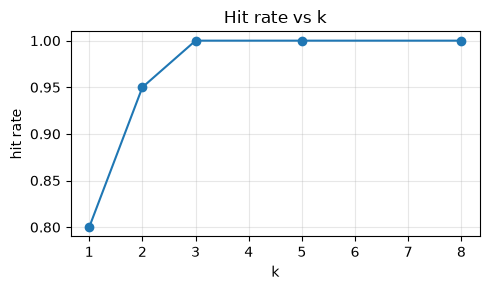

In [7]:
import matplotlib.pyplot as plt
ks = [1, 2, 3, 5, 8]
vals = [evaluate_retriever(store.search, questions, k=k)[f"hit_rate@{k}"] for k in ks]
plt.figure(figsize=(5, 3)); plt.plot(ks, vals, marker="o"); plt.xlabel("k"); plt.ylabel("hit rate"); plt.grid(alpha=.3); plt.title("Hit rate vs k"); plt.tight_layout(); plt.show()

## Compare configurations with the same harness
Once you have a harness, comparing two pipelines is one line.

In [8]:
compare_pipelines({"k=1": lambda q: rag(q, store, 1)[0], "k=3": lambda q: rag(q, store, 3)[0], "k=6": lambda q: rag(q, store, 6)[0]}, n=5)

,keyword_recall,judge_correct,avg_seconds
pipeline,,,
k=1,0.36,0.4,3.3
k=3,0.81,1.0,0.1
k=6,0.68,0.4,8.4


## Grow the golden set with synthetic questions
The LLM drafts question/answer pairs; **review them by hand** before trusting them.

In [9]:
synth = [s for s in (synth_qa(c) for c in chunks[:6]) if isinstance(s, dict) and "question" in s]
pd.DataFrame(synth)

,question,answer
0,What is a basic RAG pipeline composed of?,"four stages: ingest documents, split them into"
1,What is the purpose of embedding models in nat...,to map text to a dense vector so that texts wi...
2,How do embedding models get trained?,"contrastive learning, pulling matching pairs t..."
3,What are some approximate nearest neighbour in...,HNSW and IVF
4,What is a common approach for splitting docume...,Fixed-size chunking
5,What type of ranking function is BM25?,lexical


## Trade-offs

| Strengths | Weaknesses |
|---|---|
| Pinpoints whether retrieval or generation is failing | Golden sets need curation |
| Reusable harness for every experiment | LLM-judged correctness is noisy |
| Cheap with a small golden set | Synthetic questions can be too easy |

## When to use it

Continuously - run after every change to chunking, retrieval or prompts.

## Experiments to try

- Add context precision (fraction of retrieved chunks that are relevant).
- Track metrics over time in a CSV.
- Add human labels to a sample and measure judge agreement.

## Key takeaways

- Evaluate retrieval and generation separately.
- Attribute each failure.
- Keep the golden set in version control.

---
**Next:** [39. Open RAG Eval - Reference-free Evaluation](../39_open-rag-eval-example/open-rag-eval-example.ipynb)